# Ion fragment fractions vs photon energy — undulator scan

Does the fraction of some ion fragments change with photon energy, and does its dependence on pulse energy change?
This is the analysis of `inspect_itof_argon.ipynb` (sections 4, 5 and 5a) applied to the ion spectra of an undulator
scan, for m/q ranges chosen in the parameter cell.

**Data.** The energy-mode aggregates of an undulator scan (`compute_aggregates.py`), by default the joined AcH scan
60611 + 60612. Per cell (measured photon energy bin × GMD bin) they hold the mean ion TOF histogram `C` (10 ns bins),
its second moment `CtC`, the mean GMD `G`, the mean VLS spectrum `A` and the number of shots `n`.

**Steps.**
1. At one photon energy (`E_SEL`): the ion spectrum on m/q and TOF axes with the ranges marked; the spectrum shape per
   GMD bin; the yield of each range against the monitor with a power law $Y \propto X^p$; each range as a fraction of
   all ions and relative to `REF_RANGE`, against the monitor.
2. Against photon energy: the fraction of all ions of each range, its ratio to `REF_RANGE`, and $p$ of the yield, of the
   fraction and of the ratio to `REF_RANGE`, with errors.

**Notes.**
- Errors come from the second moments `CtC`: the error of each range's mean, and the covariance between ranges counted
  in the same shots (a range and the total share shots), are exact for the aggregated shots.
- Fractions are of *detected* ions in `TOTAL_MQ`. The ion hits are not corrected for dead time; a strong peak that
  loses hits at high pulse energy gets a lower $p$.
- $p$ comes from the aggregates' 5 GMD bins (percentile edges of the whole file, the same at every photon energy). With
  `MONITOR = "gmd"` it is affected by the noise of the hall GMD (`yield_per_uj_vs_gmd.ipynb`), so compare $p$ between
  ranges and photon energies rather than reading it as a photon order. `MONITOR = "vls"` uses the VLS line sum.
- m/q uses the ion calibration in `calibration.py` (argon run 60538, $t = t_0 + k\sqrt{m/q}$); `MQ_CAL` replaces it.
  The spectrum is also shown against TOF to check where the ranges fall.
- The scan runs monotonically in photon energy, so photon energy and acquisition time go together: a slow change of
  the target gas (composition, pressure) would look the same as a photon-energy dependence.

In [1]:
# ---- Parameters ---------------------------------------------------------------
AGG_H5 = "run60611-60612_AcH_undulator_scan_265-280eV_aggregates_energy.h5"   # relative to config.COMBINED_DIR or absolute

# m/q ranges: name -> (lo, hi). A 10 ns TOF bin counts when its centre falls inside.
MQ_RANGES = {
    "1":     (0.3, 1.6),     # H+, incl. the fast forward-emitted ones
    "2":     (1.6, 2.6),
    "12-16": (11.5, 16.5),
    "17-19": (16.5, 19.5),
    "20-22": (19.5, 22.5),
    "24-27": (23.5, 27.5),
    "28-31": (27.5, 31.5),
    "32-36": (31.5, 36.5),
    "41-44": (40.5, 44.5),
    "45-49": (44.5, 49.5),
}
TOTAL_MQ = (0.3, 50)         # "all ions", the denominator of the fractions
REF_RANGE = "28-31"          # second set of ratios: each range / this one
P_RANGES = None              # names of the ranges in the photon-energy plots (section 2); None = all
SIDEBAND_NS = 0              # > 0: subtract a linear background from side bands of this width (ns) at each range

MONITOR = "gmd"              # x of the power-law fits: "gmd" (<G>, µJ) or "vls" (VLS line sum, 10^4 ADU)
E_SEL = 270.0                # eV, photon-energy bin of section 1
MIN_SHOTS = 300              # cells with fewer shots are left out of the fits
MIN_GMD_BINS = 3             # a photon energy needs this many such GMD bins for a fit
MIN_SHOTS_E = 50000          # section 2: photon-energy bins with fewer shots are left out

MQ_CAL = None                # (t0_ns, k_ns) replacing calibration.ITOF in t = t0 + k sqrt(m/q)
MQ_MARKS = {"H+": 1.008, "CH3+": 15.023, "H2O+": 18.011, "Ar2+": 19.981, "CO+": 27.995, "CHO+": 29.003,
            "Ar+": 39.962, "CH3CO+": 43.018, "AcH+": 44.026, "EtOH+": 46.042}   # reference lines on the spectra
MAP_REBIN = 3                # shape map: merge this many 10 ns bins ...
RATIO_MIN_COUNTS = 30        # ... and blank cells with fewer hits

In [2]:
# ---- Imports and paths ------------------------------------------------------
from pathlib import Path
import sys
import warnings

import h5py
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / "analysis" / "scripts" / "config.py").exists())
sys.path.insert(0, str(REPO_ROOT / "analysis" / "scripts"))
import calibration
import config

for msg in ("invalid value encountered", "divide by zero", "Mean of empty slice", "All-NaN slice"):
    warnings.filterwarnings("ignore", message=msg)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

t0_cal, k_cal = MQ_CAL if MQ_CAL is not None else (calibration.ITOF["t0"], calibration.ITOF["k"])
tof_of = lambda mq: t0_cal + k_cal * np.sqrt(mq)                     # ns
mq_of = lambda t: ((np.asarray(t, float) - t0_cal) / k_cal) ** 2

## Load
Mean hits per shot in each range, `Y[r, e, g]`, and the per-shot covariance of the range counts, `S[r, q, e, g]`, for
every cell; the last entry of the ranges is "all ions" (`TOTAL_MQ`). `Yp`, `Sp`, `n_p`: the same with the GMD bins of
each photon energy pooled (shot-weighted).

In [3]:
p = Path(AGG_H5)
agg_path = p if p.is_absolute() else config.COMBINED_DIR / p
with h5py.File(agg_path, "r") as f:
    C = f["C"][...]                          # (nE, nG, n_tof) mean ion hits / shot per TOF bin
    CtC = f["CtC"][...]                      # (nE, nG, n_tof, n_tof) <C C^T>
    G = f["G"][...]                          # (nE, nG) mean GMD (µJ)
    n = f["n_per_bin"][...]                  # (nE, nG) shots
    V = f["A"][...].sum(-1) / 1e4 if "A" in f else np.full(G.shape, np.nan)   # mean VLS line sum (10^4 ADU)
    E_edges = f["energy_edges"][...]
    gmd_edges = f["gmd_edges"][...]
    tof_edges = f["ion_tof_edges"][...] / 10.0                     # TDC units (100 ps) -> ns
E = 0.5 * (E_edges[1:] + E_edges[:-1])
tof = 0.5 * (tof_edges[1:] + tof_edges[:-1])
mq = mq_of(tof)
X = {"gmd": G, "vls": V}[MONITOR]
x_label = {"gmd": "<G> in cell (µJ)", "vls": "<VLS line sum> in cell (10⁴ ADU)"}[MONITOR]

# weight of every TOF bin in each range (1 inside; side-band background with negative weights)
names = list(MQ_RANGES) + ["all ions"]
W = np.zeros((len(names), len(tof)))
for i, (lo, hi) in enumerate(list(MQ_RANGES.values()) + [TOTAL_MQ]):
    win = (tof >= tof_of(lo)) & (tof < tof_of(hi))
    W[i, win] = 1
    if SIDEBAND_NS > 0 and names[i] != "all ions":
        left = (tof >= tof_of(lo) - SIDEBAND_NS) & (tof < tof_of(lo))
        right = (tof >= tof_of(hi)) & (tof < tof_of(hi) + SIDEBAND_NS)
        W[i, left] -= 0.5 * win.sum() / left.sum()
        W[i, right] -= 0.5 * win.sum() / right.sum()
i_all, i_ref = len(names) - 1, names.index(REF_RANGE)
i_rng = list(range(len(MQ_RANGES)))

Y = np.einsum("rt,egt->reg", W, C)                                  # (n_names, nE, nG)
M2 = np.einsum("rt,egtq->rqeg", W, CtC @ W.T)                     # <N_r N_q> per cell
S = M2 - Y[:, None] * Y[None, :]                                    # per-shot covariance of the range counts
n_p = n.sum(axis=1)
Yp = np.nansum(Y * n, axis=2) / n_p                                 # GMD bins pooled: (n_names, nE)
Sp = np.nansum(M2 * n, axis=3) / n_p - Yp[:, None] * Yp[None, :]


def ratio(i, j, Y, S, n):
    # Y[i] / Y[j] and its error, from the per-shot (co)variances S of the two counts over n shots
    r = Y[i] / Y[j]
    rel_var = S[i, i] / Y[i] ** 2 + S[j, j] / Y[j] ** 2 - 2 * S[i, j] / (Y[i] * Y[j])
    return r, np.abs(r) * np.sqrt(rel_var / n)


def power_law(x, y, e):
    # p and its error from a weighted straight line through log y against log x (as in inspect_itof_argon)
    ok = (y > 0) & (x > 0) & np.isfinite(e) & (e > 0)
    if ok.sum() < MIN_GMD_BINS:
        return np.nan, np.nan
    c, cov = np.polyfit(np.log(x[ok]), np.log(y[ok]), 1, w=y[ok] / e[ok], cov="unscaled")
    return c[0], np.sqrt(cov[0, 0])


print(f"{agg_path.name}: {n.sum()} shots, {len(E)} photon-energy bins {E_edges[0]:.2f}-{E_edges[-1]:.2f} eV, "
      f"{n.shape[1]} GMD bins {np.round(gmd_edges, 3).tolist()} µJ")
print(f"ion TOF {tof_edges[0]:.0f}-{tof_edges[-1]:.0f} ns in {len(tof)} bins; m/q = ((t - {t0_cal:.2f}) / {k_cal:.2f})^2")
print(f"cells with >= {MIN_SHOTS} shots: {(n >= MIN_SHOTS).sum()} of {n.size}; "
      f"{np.nansum(Yp[i_all] * n_p) / n_p.sum():.3f} ions / shot in {TOTAL_MQ}")
print("\n range       m/q          TOF (ns)      bins   hits/shot (all cells)")
for i, name in enumerate(names):
    lo, hi = (list(MQ_RANGES.values()) + [TOTAL_MQ])[i]
    print(f" {name:9s}  {lo:5.1f}-{hi:5.1f}   {tof_of(lo):6.0f}-{tof_of(hi):6.0f}   {int((W[i] > 0).sum()):4d}   "
          f"{np.nansum(Yp[i] * n_p) / n_p.sum():.4f}")

run60611-60612_AcH_undulator_scan_265-280eV_aggregates_energy.h5: 17068741 shots, 39 photon-energy bins 263.75-283.25 eV, 5 GMD bins [0.02, 0.089, 0.183, 0.333, 0.615, 5.486] µJ
ion TOF 200-3400 ns in 320 bins; m/q = ((t - -18.42) / 481.37)^2
cells with >= 300 shots: 171 of 195; 0.873 ions / shot in (0.3, 50)

 range       m/q          TOF (ns)      bins   hits/shot (all cells)
 1            0.3-  1.6      245-   590     34   0.0813
 2            1.6-  2.6      590-   758     17   0.0183
 12-16       11.5- 16.5     1614-  1937     33   0.1266
 17-19       16.5- 19.5     1937-  2107     17   0.0537
 20-22       19.5- 22.5     2107-  2265     15   0.0815
 24-27       23.5- 27.5     2315-  2506     19   0.0612
 28-31       27.5- 31.5     2506-  2683     17   0.1539
 32-36       31.5- 36.5     2683-  2890     21   0.0999
 41-44       40.5- 44.5     3045-  3193     15   0.0419
 45-49       44.5- 49.5     3193-  3368     18   0.0782
 all ions     0.3- 50.0      245-  3385    314   0.8729


## 1. One photon energy
The photon-energy bin holding `E_SEL`. The spectrum is the mean over its GMD bins; the shaded bands are `MQ_RANGES`,
the grey lines `MQ_MARKS`.

photon-energy bin 269.75-270.25 eV: 672435 shots, per GMD bin [93709, 110232, 131279, 156705, 180510]


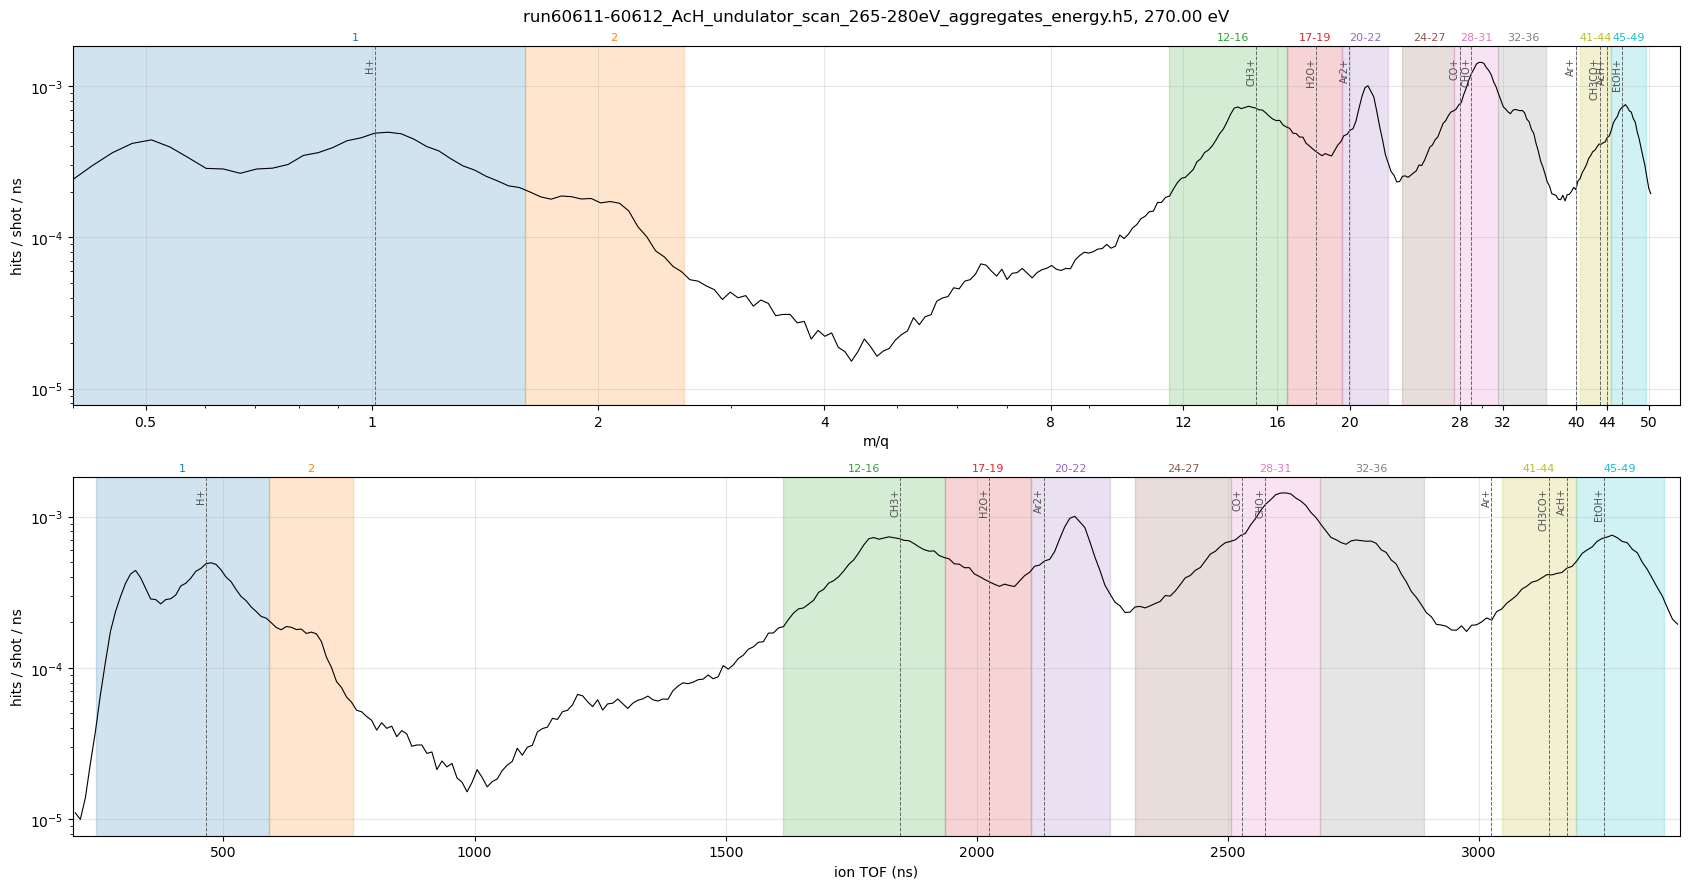

In [4]:
ie = int(np.clip(np.searchsorted(E_edges, E_SEL) - 1, 0, len(E) - 1))
ne = n[ie]
spec = np.nansum(C[ie] * ne[:, None], axis=0) / ne.sum() / np.diff(tof_edges)   # hits / shot / ns
print(f"photon-energy bin {E_edges[ie]:.2f}-{E_edges[ie + 1]:.2f} eV: {ne.sum()} shots, per GMD bin {ne.tolist()}")

fig, axs = plt.subplots(2, 1, figsize=(17, 9))
for ax, xs, xlim in ((axs[0], mq, (0.4, 55)), (axs[1], tof, (tof_edges[0], tof_edges[-1]))):
    ax.plot(xs, spec, color="k", lw=0.8)
    for k, (name, (lo, hi)) in enumerate(MQ_RANGES.items()):
        a, b = (lo, hi) if ax is axs[0] else (tof_of(lo), tof_of(hi))
        ax.axvspan(a, b, color=f"C{k % 10}", alpha=0.2)
        ax.text(0.5 * (a + b), 1.01, name, color=f"C{k % 10}", ha="center", va="bottom", fontsize=8,
                transform=ax.get_xaxis_transform())
    for name, m in MQ_MARKS.items():
        xm = m if ax is axs[0] else tof_of(m)
        ax.axvline(xm, color="0.4", lw=0.7, ls="--")
        ax.text(xm, 0.97, name, color="0.3", fontsize=7, rotation=90, ha="right", va="top",
                transform=ax.get_xaxis_transform())
    ax.set(yscale="log", xlim=xlim, ylabel="hits / shot / ns")
axs[0].set(xscale="log", xlabel="m/q")
axs[0].set_xticks([0.5, 1, 2, 4, 8, 12, 16, 20, 28, 32, 40, 44, 50], ["0.5", "1", "2", "4", "8", "12", "16", "20", "28",
                                                                     "32", "40", "44", "50"])
axs[1].set(xlabel="ion TOF (ns)")
axs[0].set_title(f"{agg_path.name}, {E[ie]:.2f} eV", pad=18)
fig.tight_layout()
plt.show()

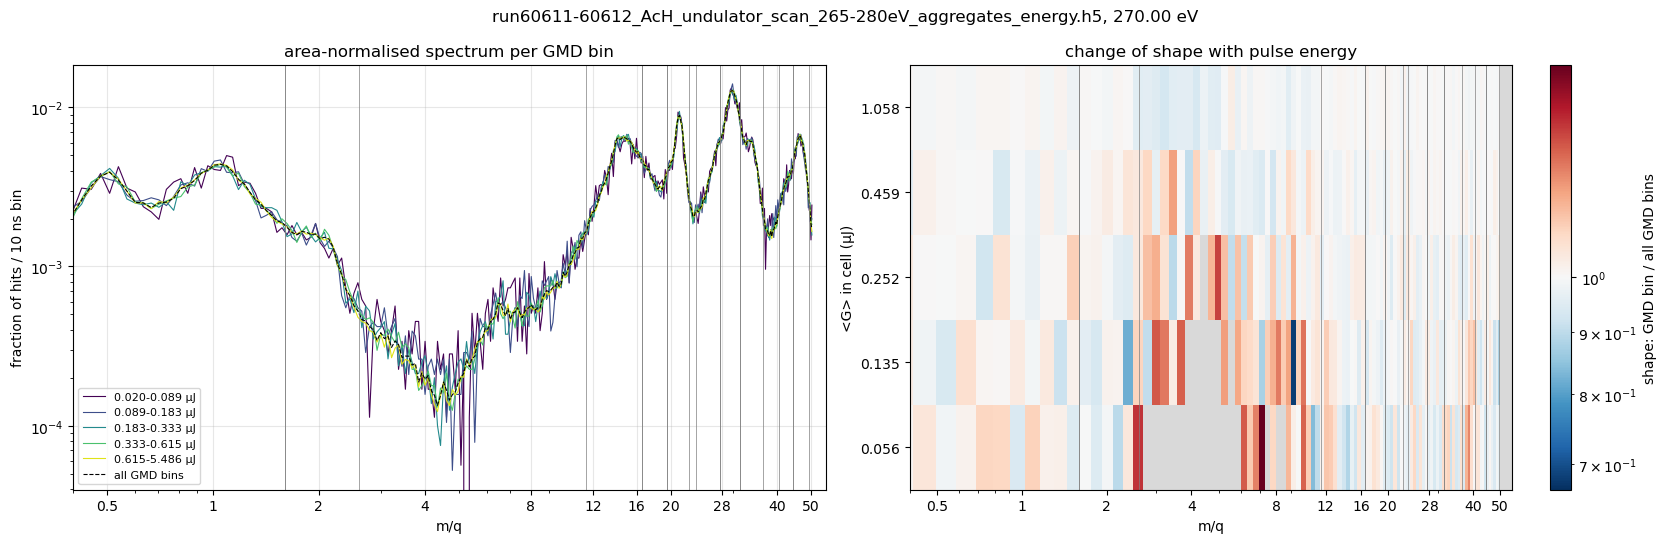

In [5]:
# Spectrum shape per GMD bin: area-normalised (left) and divided by the mean over the GMD bins (right)
counts = C[ie] * ne[:, None]                              # hits per TOF bin, per GMD bin
area = counts / counts.sum(axis=1, keepdims=True)
area_all = counts.sum(axis=0) / counts.sum()
nr = (counts.shape[1] // MAP_REBIN) * MAP_REBIN
c_r = counts[:, :nr].reshape(len(ne), -1, MAP_REBIN).sum(-1)
a_r = c_r.sum(axis=0)
shape = (c_r / c_r.sum(axis=1, keepdims=True)) / np.where(a_r > 0, a_r / a_r.sum(), np.nan)
shape[c_r < RATIO_MIN_COUNTS] = np.nan
cols = mpl.colormaps["viridis"](np.linspace(0, 0.95, len(ne)))

fig, axs = plt.subplots(1, 2, figsize=(17, 5.5))
for g in range(len(ne)):
    axs[0].plot(mq, area[g], color=cols[g], lw=0.8, label=f"{gmd_edges[g]:.3f}-{gmd_edges[g + 1]:.3f} µJ")
axs[0].plot(mq, area_all, "k--", lw=0.8, label="all GMD bins")
axs[0].set(xscale="log", yscale="log", xlim=(0.4, 55), xlabel="m/q", ylabel="fraction of hits / 10 ns bin",
           title="area-normalised spectrum per GMD bin")
axs[0].legend(fontsize=8)
mesh = axs[1].pcolormesh(mq_of(tof_edges[:nr + 1:MAP_REBIN]), np.arange(len(ne) + 1), shape,
                         shading="flat", cmap="RdBu_r", norm=mpl.colors.LogNorm(1 / 1.5, 1.5))
fig.colorbar(mesh, ax=axs[1], label="shape: GMD bin / all GMD bins")
axs[1].set_facecolor("0.85")
axs[1].set_yticks(np.arange(len(ne)) + 0.5, [f"{x:.3f}" for x in X[ie]])
axs[1].set(xscale="log", xlim=(0.4, 55), xlabel="m/q", ylabel=x_label, title="change of shape with pulse energy")
axs[1].grid(False)
for ax in axs:
    ax.set_xticks([0.5, 1, 2, 4, 8, 12, 16, 20, 28, 40, 50], ["0.5", "1", "2", "4", "8", "12", "16", "20", "28", "40", "50"])
    for lo, hi in MQ_RANGES.values():
        ax.axvline(lo, color="0.5", lw=0.5)
        ax.axvline(hi, color="0.5", lw=0.5)
fig.suptitle(f"{agg_path.name}, {E[ie]:.2f} eV")
fig.tight_layout()
plt.show()

5 GMD bins with >= 300 shots; monitor: 0.056  0.135  0.252  0.459  1.058
 range       hits/shot (pooled)   p yield          fraction (pooled)   p fraction       chi2/dof   / 28-31 (pooled)   p
 1           0.1105             0.950 ± 0.005    0.0980              -0.003 ± 0.005     0.89     0.5750           -0.008 ± 0.006
 2           0.0245             0.956 ± 0.011    0.0218              +0.002 ± 0.011     0.59     0.1277           -0.002 ± 0.011
 12-16       0.1674             0.957 ± 0.004    0.1485              +0.003 ± 0.004     0.89     0.8715           -0.001 ± 0.006
 17-19       0.0696             0.963 ± 0.006    0.0618              +0.009 ± 0.006     1.40     0.3625           +0.005 ± 0.007
 20-22       0.0991             0.960 ± 0.005    0.0880              +0.006 ± 0.005     0.45     0.5160           +0.001 ± 0.007
 24-27       0.0795             0.954 ± 0.006    0.0705              -0.000 ± 0.006     0.02     0.4138           -0.004 ± 0.007
 28-31       0.1921             0

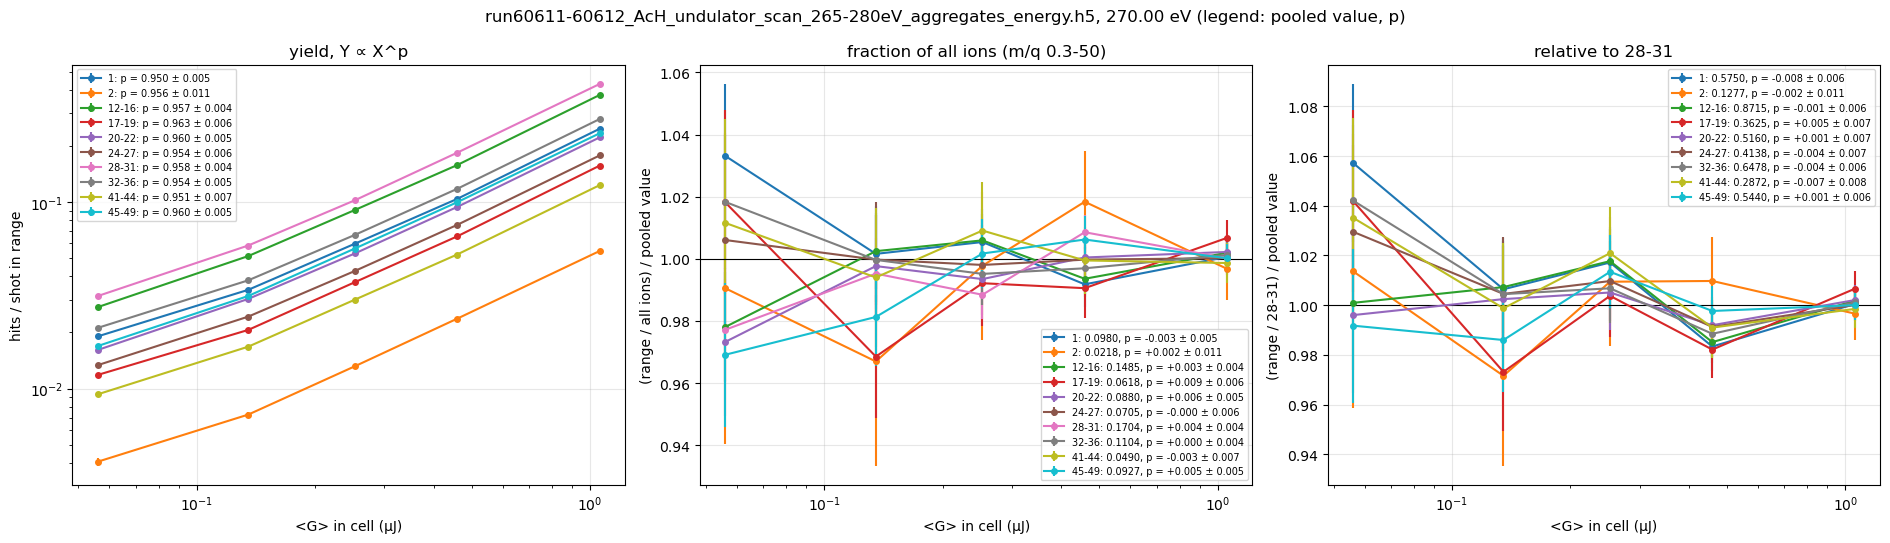

In [6]:
# Yields, fractions of all ions and ratios to REF_RANGE against the monitor, at E_SEL
ok = ne >= MIN_SHOTS
x = X[ie, ok]
Yc, Sc, nc = Y[:, ie, ok], S[:, :, ie, ok], ne[ok]
print(f"{ok.sum()} GMD bins with >= {MIN_SHOTS} shots; monitor: " + "  ".join(f"{v:.3f}" for v in x))
print(" range       hits/shot (pooled)   p yield          fraction (pooled)   p fraction       chi2/dof   "
      f"/ {REF_RANGE} (pooled)   p")
fig, axs = plt.subplots(1, 3, figsize=(19, 5.5))
for i in i_rng:
    col = f"C{i % 10}"
    y, e = Yc[i], np.sqrt(Sc[i, i] / nc)
    p_y = power_law(x, y, e)
    f_, fe = ratio(i, i_all, Yc, Sc, nc)
    f0 = Yp[i, ie] / Yp[i_all, ie]
    p_f = power_law(x, f_, fe)
    w = 1 / fe ** 2
    chi2 = np.sum(w * (f_ - np.sum(w * f_) / np.sum(w)) ** 2) / (len(f_) - 1)
    axs[0].errorbar(x, y, e, fmt="o-", ms=4, color=col, label=f"{names[i]}: p = {p_y[0]:.3f} ± {p_y[1]:.3f}")
    axs[1].errorbar(x, f_ / f0, fe / f0, fmt="o-", ms=4, color=col,
                    label=f"{names[i]}: {f0:.4f}, p = {p_f[0]:+.3f} ± {p_f[1]:.3f}")
    line = (f" {names[i]:9s}   {Yp[i, ie]:.4f}             {p_y[0]:.3f} ± {p_y[1]:.3f}    {f0:.4f}              "
            f"{p_f[0]:+.3f} ± {p_f[1]:.3f}   {chi2:6.2f}")
    if i != i_ref:
        r_, re = ratio(i, i_ref, Yc, Sc, nc)
        r0 = Yp[i, ie] / Yp[i_ref, ie]
        p_r = power_law(x, r_, re)
        axs[2].errorbar(x, r_ / r0, re / r0, fmt="o-", ms=4, color=col,
                        label=f"{names[i]}: {r0:.4f}, p = {p_r[0]:+.3f} ± {p_r[1]:.3f}")
        line += f"     {r0:.4f}           {p_r[0]:+.3f} ± {p_r[1]:.3f}"
    print(line)
axs[0].set(xscale="log", yscale="log", xlabel=x_label, ylabel="hits / shot in range", title="yield, Y ∝ X^p")
axs[1].set(xscale="log", xlabel=x_label, ylabel="(range / all ions) / pooled value",
           title=f"fraction of all ions (m/q {TOTAL_MQ[0]}-{TOTAL_MQ[1]})")
axs[2].set(xscale="log", xlabel=x_label, ylabel=f"(range / {REF_RANGE}) / pooled value", title=f"relative to {REF_RANGE}")
for ax in axs:
    ax.legend(fontsize=7)
for ax in axs[1:]:
    ax.axhline(1, color="k", lw=0.8)
fig.suptitle(f"{agg_path.name}, {E[ie]:.2f} eV (legend: pooled value, p)")
fig.tight_layout()
plt.show()

## 2. Against photon energy
Left: each range as a fraction of all ions, with the GMD bins of each photon energy pooled. Middle and right: the same
fraction and the ratio to `REF_RANGE`, each divided by its value for the whole scan, so a change with photon energy
shows on a linear scale. Photon-energy bins with fewer than `MIN_SHOTS_E` shots are left out. The second figure shows $p$
of the yield, of the fraction of all ions and of the ratio to `REF_RANGE`, from the GMD bins with at least
`MIN_SHOTS` shots, for the ranges in `P_RANGES`.

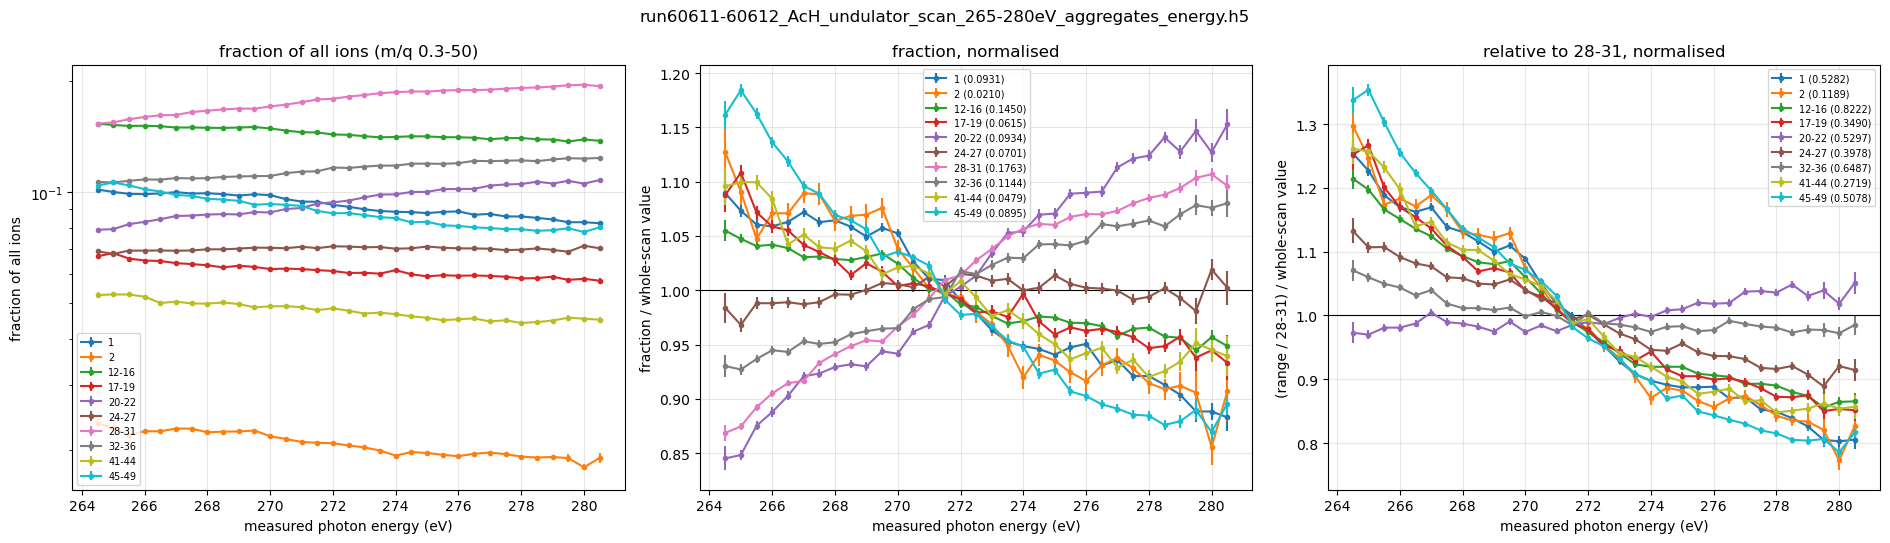

In [7]:
sel = [names.index(r) for r in (P_RANGES if P_RANGES is not None else MQ_RANGES)]
use_e = n_p >= MIN_SHOTS_E
Y_tot = np.nansum(Yp * n_p, axis=1) / n_p.sum()             # whole scan

fig, axs = plt.subplots(1, 3, figsize=(19, 5.5))
for i in sel:
    col = f"C{i % 10}"
    f_, fe = ratio(i, i_all, Yp, Sp, n_p)
    f_[~use_e] = np.nan
    f0 = Y_tot[i] / Y_tot[i_all]
    axs[0].errorbar(E, f_, fe, fmt="o-", ms=3, color=col, label=names[i])
    axs[1].errorbar(E, f_ / f0, fe / f0, fmt="o-", ms=3, color=col, label=f"{names[i]} ({f0:.4f})")
    if i != i_ref:
        r_, re = ratio(i, i_ref, Yp, Sp, n_p)
        r_[~use_e] = np.nan
        r0 = Y_tot[i] / Y_tot[i_ref]
        axs[2].errorbar(E, r_ / r0, re / r0, fmt="o-", ms=3, color=col, label=f"{names[i]} ({r0:.4f})")
axs[0].set(yscale="log", ylabel="fraction of all ions", title=f"fraction of all ions (m/q {TOTAL_MQ[0]}-{TOTAL_MQ[1]})")
axs[1].set(ylabel="fraction / whole-scan value", title="fraction, normalised")
axs[2].set(ylabel=f"(range / {REF_RANGE}) / whole-scan value", title=f"relative to {REF_RANGE}, normalised")
for ax in axs:
    ax.set_xlabel("measured photon energy (eV)")
    ax.legend(fontsize=7)
for ax in axs[1:]:
    ax.axhline(1, color="k", lw=0.8)
fig.suptitle(agg_path.name)
fig.tight_layout()
plt.show()

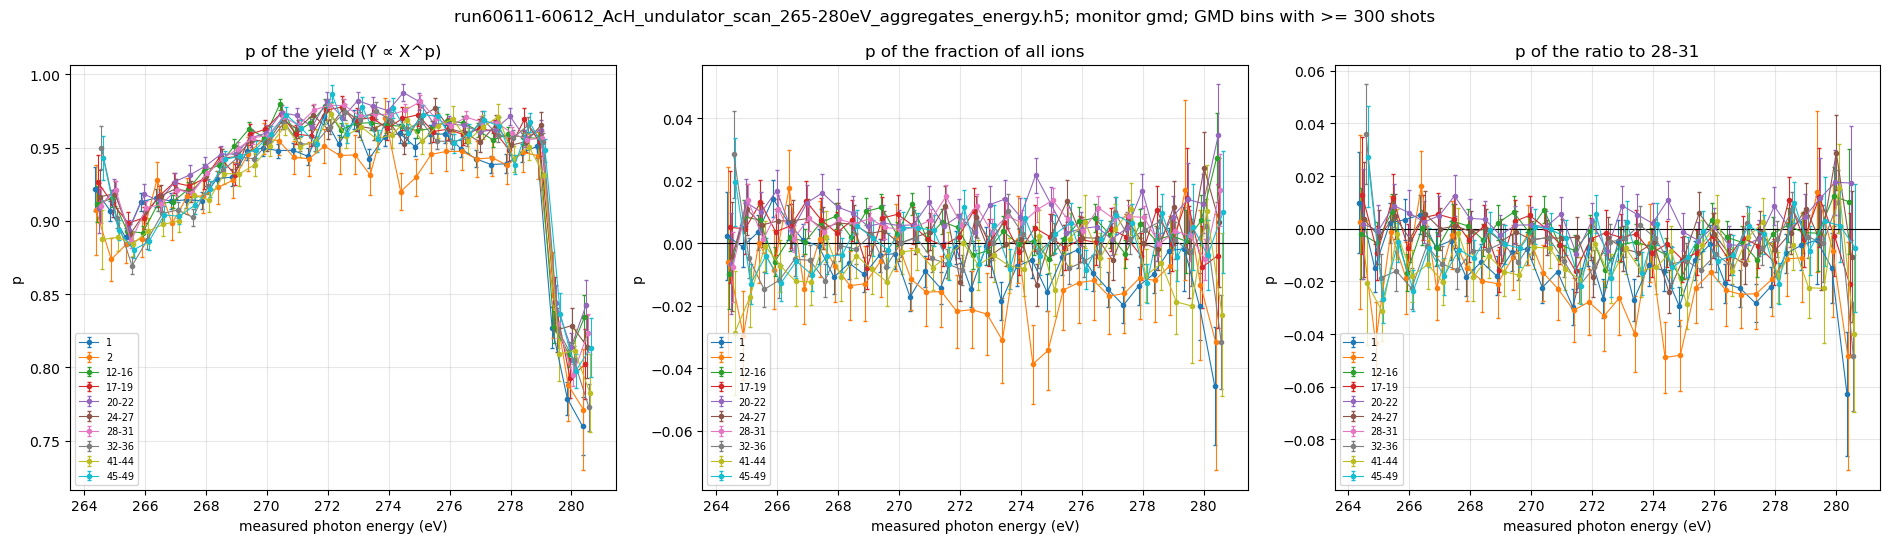

p of the yield (rows: photon energy; error in brackets)
   E (eV)                1               2           12-16           17-19           20-22           24-27           28-31           32-36           41-44           45-49
   264.50    0.922 (0.015)   0.907 (0.031)   0.912 (0.012)   0.927 (0.019)   0.909 (0.017)   0.917 (0.018)   0.911 (0.012)   0.950 (0.015)   0.887 (0.020)   0.943 (0.015)
   265.00    0.907 (0.007)   0.874 (0.014)   0.916 (0.006)   0.911 (0.008)   0.921 (0.008)   0.919 (0.009)   0.921 (0.006)   0.902 (0.007)   0.889 (0.010)   0.894 (0.007)
   265.50    0.889 (0.006)   0.884 (0.013)   0.893 (0.005)   0.899 (0.007)   0.894 (0.007)   0.891 (0.007)   0.886 (0.005)   0.869 (0.006)   0.884 (0.008)   0.880 (0.006)
   266.00    0.913 (0.006)   0.888 (0.013)   0.892 (0.005)   0.902 (0.008)   0.918 (0.007)   0.906 (0.007)   0.909 (0.005)   0.887 (0.006)   0.893 (0.009)   0.886 (0.006)
   266.50    0.916 (0.006)   0.928 (0.012)   0.911 (0.005)   0.917 (0.007)   0.913 (0.006

In [8]:
# p against photon energy: yield, fraction of all ions, ratio to REF_RANGE
P = np.full((3, len(names), len(E), 2), np.nan)             # (yield / fraction / ratio to ref, range, energy, [p, err])
for e_ in range(len(E)):
    ok = n[e_] >= MIN_SHOTS
    if ok.sum() < MIN_GMD_BINS or n_p[e_] < MIN_SHOTS_E:
        continue
    x = X[e_, ok]
    Yc, Sc, nc = Y[:, e_, ok], S[:, :, e_, ok], n[e_, ok]
    for i in sel:
        P[0, i, e_] = power_law(x, Yc[i], np.sqrt(Sc[i, i] / nc))
        P[1, i, e_] = power_law(x, *ratio(i, i_all, Yc, Sc, nc))
        if i != i_ref:
            P[2, i, e_] = power_law(x, *ratio(i, i_ref, Yc, Sc, nc))

fig, axs = plt.subplots(1, 3, figsize=(19, 5.5))
titles = ["p of the yield (Y ∝ X^p)", "p of the fraction of all ions", f"p of the ratio to {REF_RANGE}"]
for k, ax in enumerate(axs):
    for j, i in enumerate(sel):
        dx = (j - (len(sel) - 1) / 2) * 0.03                  # small offsets so the error bars do not overlap
        ax.errorbar(E + dx, P[k, i, :, 0], P[k, i, :, 1], fmt="o-", ms=3, lw=0.8, capsize=1.5,
                    color=f"C{i % 10}", label=names[i])
    if k > 0:
        ax.axhline(0, color="k", lw=0.8)
    ax.set(xlabel="measured photon energy (eV)", ylabel="p", title=titles[k])
    ax.legend(fontsize=7)
fig.suptitle(f"{agg_path.name}; monitor {MONITOR}; GMD bins with >= {MIN_SHOTS} shots")
fig.tight_layout()
plt.show()

print("p of the yield (rows: photon energy; error in brackets)")
print("   E (eV) " + "".join(f"{names[i]:>16s}" for i in sel))
for e_ in range(len(E)):
    if np.isfinite(P[0, sel, e_, 0]).any():
        print(f"  {E[e_]:7.2f} " + "".join(f"  {P[0, i, e_, 0]:6.3f} ({P[0, i, e_, 1]:.3f})" for i in sel))

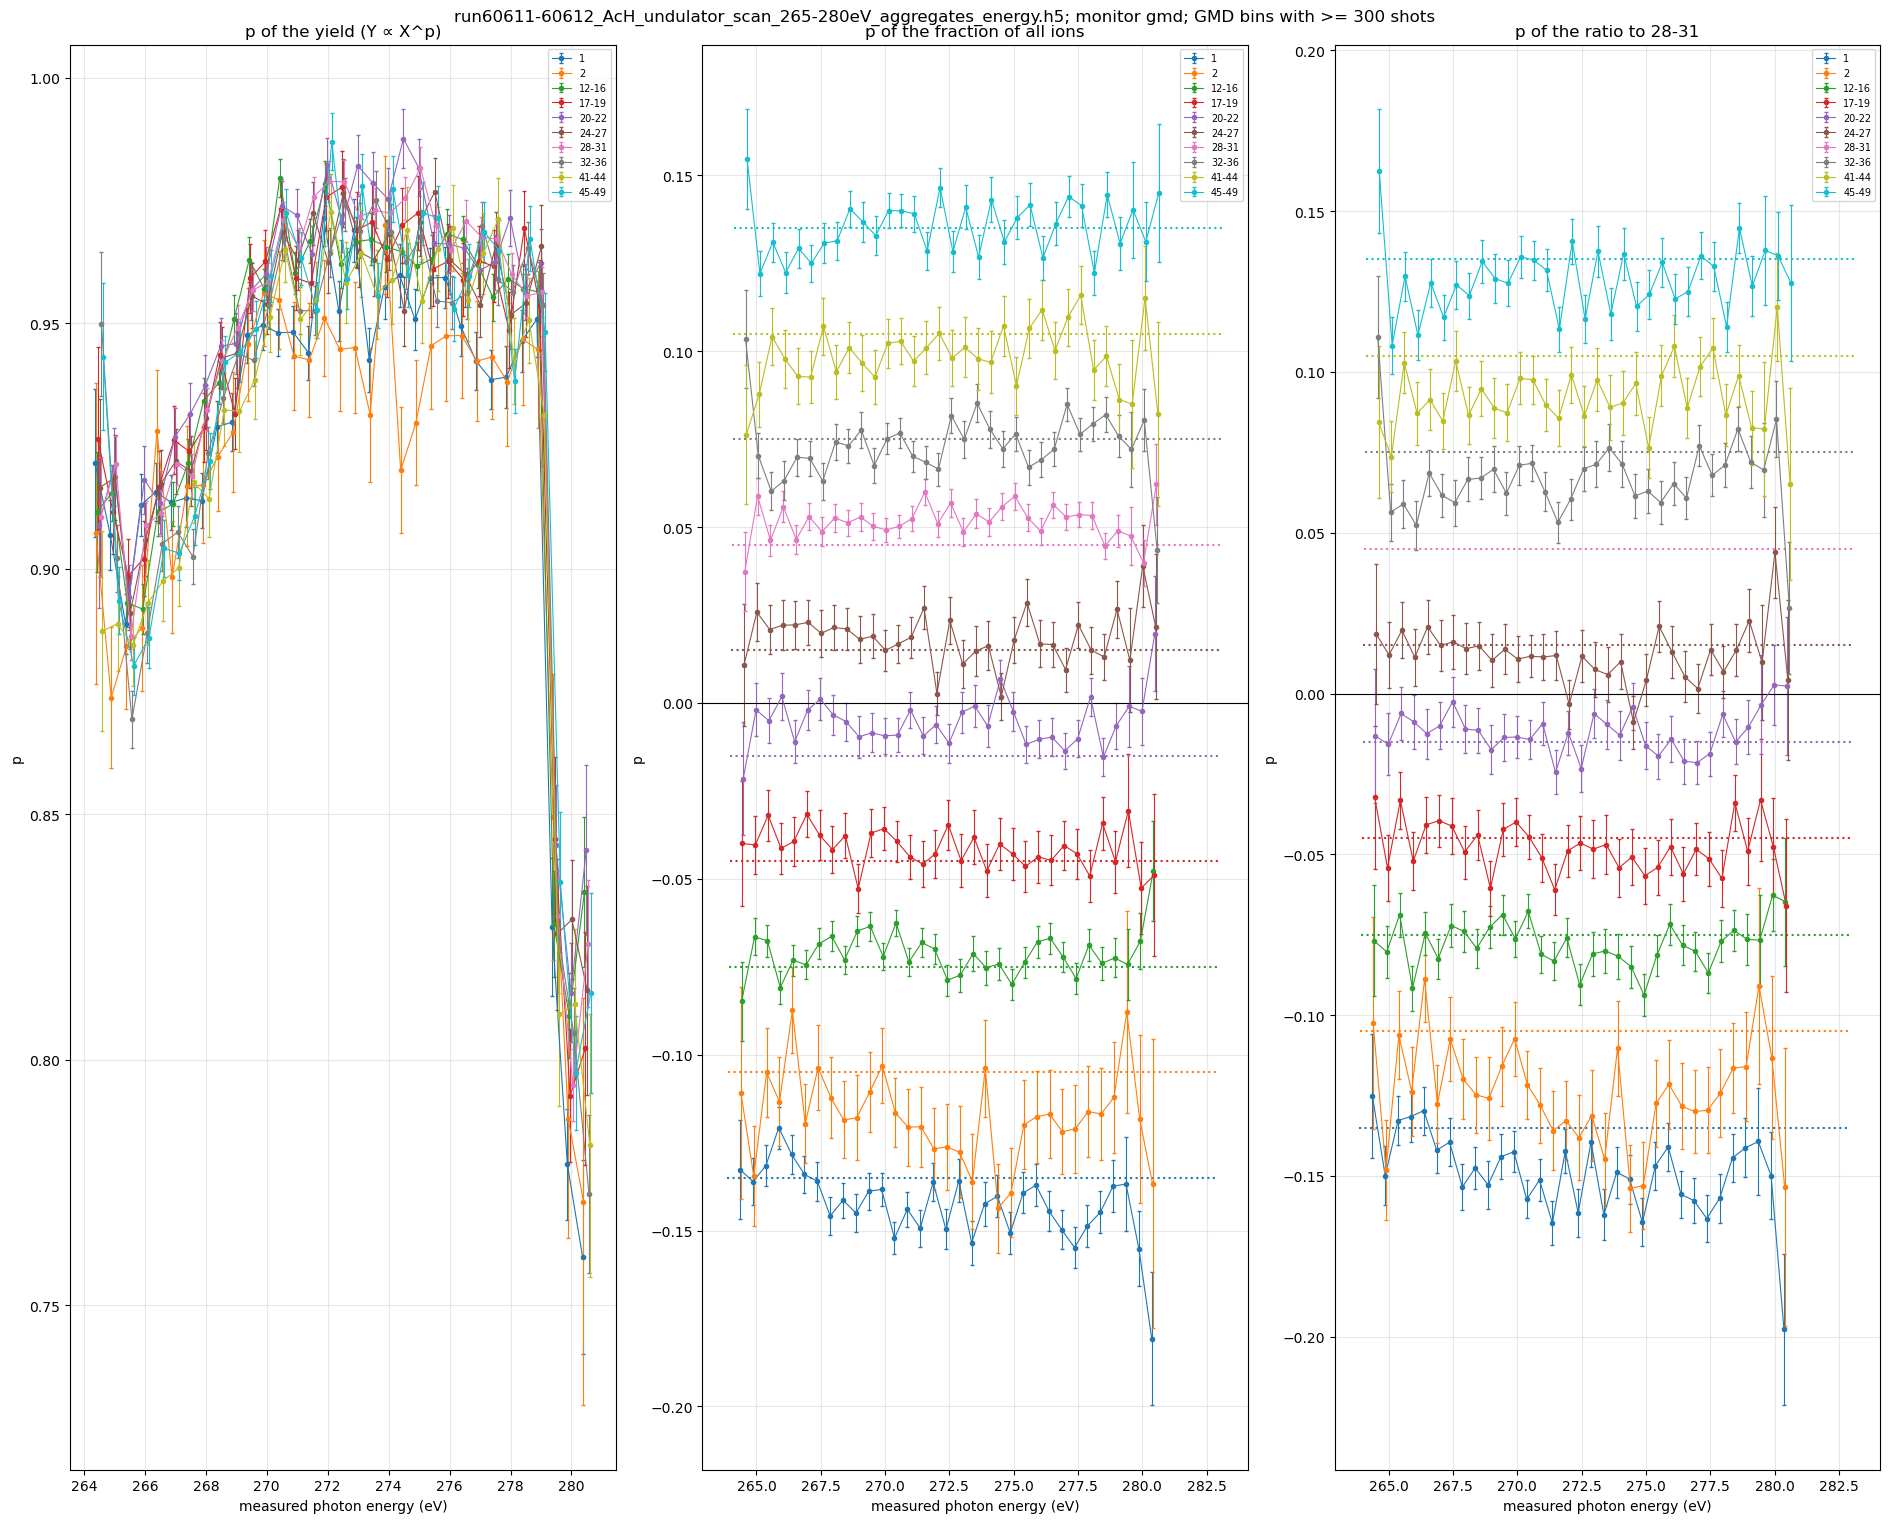

p of the yield (rows: photon energy; error in brackets)
   E (eV)                1               2           12-16           17-19           20-22           24-27           28-31           32-36           41-44           45-49
   264.50    0.922 (0.015)   0.907 (0.031)   0.912 (0.012)   0.927 (0.019)   0.909 (0.017)   0.917 (0.018)   0.911 (0.012)   0.950 (0.015)   0.887 (0.020)   0.943 (0.015)
   265.00    0.907 (0.007)   0.874 (0.014)   0.916 (0.006)   0.911 (0.008)   0.921 (0.008)   0.919 (0.009)   0.921 (0.006)   0.902 (0.007)   0.889 (0.010)   0.894 (0.007)
   265.50    0.889 (0.006)   0.884 (0.013)   0.893 (0.005)   0.899 (0.007)   0.894 (0.007)   0.891 (0.007)   0.886 (0.005)   0.869 (0.006)   0.884 (0.008)   0.880 (0.006)
   266.00    0.913 (0.006)   0.888 (0.013)   0.892 (0.005)   0.902 (0.008)   0.918 (0.007)   0.906 (0.007)   0.909 (0.005)   0.887 (0.006)   0.893 (0.009)   0.886 (0.006)
   266.50    0.916 (0.006)   0.928 (0.012)   0.911 (0.005)   0.917 (0.007)   0.913 (0.006

In [17]:
# p against photon energy: yield, fraction of all ions, ratio to REF_RANGE
P = np.full((3, len(names), len(E), 2), np.nan)             # (yield / fraction / ratio to ref, range, energy, [p, err])
for e_ in range(len(E)):
    ok = n[e_] >= MIN_SHOTS
    if ok.sum() < MIN_GMD_BINS or n_p[e_] < MIN_SHOTS_E:
        continue
    x = X[e_, ok]
    Yc, Sc, nc = Y[:, e_, ok], S[:, :, e_, ok], n[e_, ok]
    for i in sel:
        P[0, i, e_] = power_law(x, Yc[i], np.sqrt(Sc[i, i] / nc))
        P[1, i, e_] = power_law(x, *ratio(i, i_all, Yc, Sc, nc))
        if i != i_ref:
            P[2, i, e_] = power_law(x, *ratio(i, i_ref, Yc, Sc, nc))

fig, axs = plt.subplots(1, 3, figsize=(19, 15.5))
titles = ["p of the yield (Y ∝ X^p)", "p of the fraction of all ions", f"p of the ratio to {REF_RANGE}"]
for k, ax in enumerate(axs):
    for j, i in enumerate(sel):
        dx = (j - (len(sel) - 1) / 2) * 0.03                  # small offsets so the error bars do not overlap
        if k > 0:
            dy = (j - (len(sel) - 1) / 2) * 0.03                  # small offsets so the error bars do not overlap
            ax.plot(E + dx, dy*np.ones_like(E), color=f"C{i % 10}", ls=':', ms=0, label='__')
        else: dy = 0

        ax.errorbar(E + dx, dy + P[k, i, :, 0], P[k, i, :, 1], fmt="o-", ms=3, lw=0.8, capsize=1.5,
                    color=f"C{i % 10}", label=names[i])
    if k > 0:
        ax.axhline(0, color="k", lw=0.8)
    ax.set(xlabel="measured photon energy (eV)", ylabel="p", title=titles[k])
    ax.legend(fontsize=7)
fig.suptitle(f"{agg_path.name}; monitor {MONITOR}; GMD bins with >= {MIN_SHOTS} shots")
fig.tight_layout()
plt.show()

print("p of the yield (rows: photon energy; error in brackets)")
print("   E (eV) " + "".join(f"{names[i]:>16s}" for i in sel))
for e_ in range(len(E)):
    if np.isfinite(P[0, sel, e_, 0]).any():
        print(f"  {E[e_]:7.2f} " + "".join(f"  {P[0, i, e_, 0]:6.3f} ({P[0, i, e_, 1]:.3f})" for i in sel))

In [13]:
E

array([264. , 264.5, 265. , 265.5, 266. , 266.5, 267. , 267.5, 268. ,
       268.5, 269. , 269.5, 270. , 270.5, 271. , 271.5, 272. , 272.5,
       273. , 273.5, 274. , 274.5, 275. , 275.5, 276. , 276.5, 277. ,
       277.5, 278. , 278.5, 279. , 279.5, 280. , 280.5, 281. , 281.5,
       282. , 282.5, 283. ])